# Object Tracking

The `mediatools.vision` subpackage provides a typed interface for multi-object tracking backed by `ultralytics`. Raw model output is converted immediately into immutable domain objects, so the rest of your code never touches untyped library results.

**What you'll learn:**
- How to track objects in a video or frame by frame with `ObjectTracker`
- How to work with the immutable `TrackedFrame`, `TrackedObject`, and `BoundingBox` types
- How to tune tracker, model, and input size for persistent tracks (especially with a moving camera)
- How to track only certain classes, such as people
- How to use a GPU, and which models and settings run on an 8 GB card

**Installation:** this component is optional because of its heavy dependencies. Install it with `pip install "mediatools[vision]"` or `uv sync --extra vision`. The extra uses `opencv-python-headless`, so no system GUI libraries (such as `libGL`) are required. Importing `mediatools.vision` without the extra raises an `ImportError` that names the missing extra.

In [1]:
from mediatools.vision import ObjectTracker

#### Load Test Data
First, let's download some public video files for demonstration.

In [2]:
from pathlib import Path

# get environment variables for testing
import pydantic_settings
class Settings(pydantic_settings.BaseSettings):
    test_zip_file_url: str
settings = Settings()

# download zip file and dump it into a temporary directory
from example_helpers import RemoteZipDownloader
zd = RemoteZipDownloader.from_url(settings.test_zip_file_url)
temp_path = zd.path

ex_vid = temp_path / "totk_builds/op_builds.mp4"
ex_vid

PosixPath('/tmp/tmpzd162qq8/totk_builds/op_builds.mp4')

## The Tracker

`ObjectTracker` wraps a YOLO model and a tracker configuration. The model weights are downloaded automatically on first use.

| Argument | Default | Purpose |
|---|---|---|
| `model` | `"yolo11n.pt"` | YOLO weights. Larger variants (`yolo11s/m/l/x.pt`) are more accurate but slower and use more memory. |
| `tracker` | `"bytetrack.yaml"` | Tracker config: `"bytetrack.yaml"`, `"botsort.yaml"`, or a path to a custom YAML file. |
| `conf` | `0.25` | Minimum detection confidence. |
| `classes` | `None` | Optional class IDs to keep (COCO `person` is `0`). The filter is applied inside the model, so other classes are never detected or tracked. |
| `imgsz` | `640` | Detector input size in pixels (a multiple of 32). Larger values find smaller objects. |

The tracker keeps state between calls so identities persist across frames. Create one `ObjectTracker` per video or stream.

In [3]:
tracker = ObjectTracker(model="yolo11n.pt", tracker="bytetrack.yaml", conf=0.25)

## Tracking a Video

`track_video` lazily yields one `TrackedFrame` per video frame. Here we take the first 30 frames with `itertools.islice`.

In [4]:
from itertools import islice

frames = tuple(islice(tracker.track_video(ex_vid), 30))
len(frames)

30

### `TrackedFrame` and `TrackedObject`

A `TrackedFrame` is an immutable tuple of `TrackedObject` instances. Each object carries a `track_id` that stays consistent across frames, a class, a confidence score, and a `BoundingBox`.

In [5]:
frames[-1]

(TrackedObject(track_id=7, class_id=2, class_name='car', confidence=0.41940271854400635, bounding_box=BoundingBox(x_min=212.72801208496094, y_min=212.77627563476562, x_max=298.14947509765625, y_max=266.9924621582031)),
 TrackedObject(track_id=6, class_id=0, class_name='person', confidence=0.29722684621810913, bounding_box=BoundingBox(x_min=256.12548828125, y_min=212.14089965820312, x_max=277.4417724609375, y_max=265.3086853027344)))

In [6]:
for obj in frames[-1]:
    box = obj.bounding_box
    print(f"ID {obj.track_id:03d} | {obj.class_name} ({obj.confidence:.2f}) | "
          f"({box.x_min:.0f}, {box.y_min:.0f}) -> ({box.x_max:.0f}, {box.y_max:.0f})")

ID 007 | car (0.42) | (213, 213) -> (298, 267)
ID 006 | person (0.30) | (256, 212) -> (277, 265)


## Summarizing Tracks

Because the results are plain typed objects, ordinary Python is enough to analyze them. Here we count how many frames each track appears in.

In [7]:
from collections import Counter

frames_per_track = Counter(obj.track_id for frame in frames for obj in frame)
class_per_track = {obj.track_id: obj.class_name for frame in frames for obj in frame}

[(tid, class_per_track[tid], n) for tid, n in frames_per_track.most_common()]

[(7, 'car', 12),
 (1, 'person', 8),
 (6, 'person', 5),
 (3, 'person', 3),
 (2, 'person', 2)]

## Tuning for Persistent Tracks

If objects frequently lose their ID (one real object appearing as several tracks), these settings matter most:

- **Tracker:** `bytetrack.yaml` has no camera-motion compensation. For handheld or moving cameras (GoPro, phone), use `botsort.yaml`, which compensates for global motion.
- **Input size (`imgsz`):** the detector resizes each frame. In high-resolution video, small or distant objects disappear at the default `640` and reappear later as new tracks. Try `1280` or `1920`.
- **Model size:** larger models give steadier detections, which gives the tracker less to repair.
- **Confidence (`conf`):** a lower value (such as `0.1`) keeps weak detections that the tracker can still associate, reducing gaps. Raise it if you see false boxes.
- **Track buffer and ReID:** a custom tracker YAML can keep lost tracks alive longer and use appearance features to re-link them (see below).

Unique track count and mean track length are a useful proxy for comparing settings on the same frames: fewer, longer tracks means less fragmentation. They do not tell you whether identities are correct, so also check the boxes visually (see the visualization section). As an example, on 300 frames of handheld GoPro footage (people only), mean track length rose from 32.4 frames with ByteTrack at `imgsz=640` to 42.4 frames with BoT-SORT at `imgsz=1280`. Results on the sample clip used in this notebook will differ.

In [8]:
def track_stats(frames):
    """Return (unique track count, mean track length in frames)."""
    lengths = Counter(obj.track_id for frame in frames for obj in frame)
    return len(lengths), sum(lengths.values()) / max(len(lengths), 1)

# each tracker needs its own ObjectTracker instance
for cfg in ("bytetrack.yaml", "botsort.yaml"):
    cmp_tracker = ObjectTracker(tracker=cfg, imgsz=1280)
    sample = tuple(islice(cmp_tracker.track_video(ex_vid), 30))
    print(cfg, track_stats(sample))

bytetrack.yaml (2, 4.5)
botsort.yaml (2, 4.5)


### Custom Tracker Configuration and Class Filtering

For a custom setup, pass the path of a tracker YAML file as `tracker`. The configuration below is BoT-SORT tuned for a moving camera and long occlusions:

- `gmc_method: sparseOptFlow` compensates for camera motion
- `track_buffer: 90` keeps lost tracks alive for about 3 seconds at 30 fps so they can be re-matched
- `with_reid: True` with a lowered `appearance_thresh` lets appearance features re-link lost tracks (slower than motion-only tracking)
- `new_track_thresh` is raised above `track_high_thresh` so weak detections do not spawn new IDs

Use `classes` to restrict tracking to specific class IDs. Here we track only people (COCO class `0`).

In [9]:
import tempfile

PERSISTENT_BOTSORT = """\
tracker_type: botsort
track_high_thresh: 0.3
track_low_thresh: 0.1
new_track_thresh: 0.4
track_buffer: 90
match_thresh: 0.85
fuse_score: True
gmc_method: sparseOptFlow
proximity_thresh: 0.5
appearance_thresh: 0.25
with_reid: True
model: auto
"""

config_path = Path(tempfile.mkdtemp()) / "botsort_persistent.yaml"
config_path.write_text(PERSISTENT_BOTSORT)

people_tracker = ObjectTracker(
    model="yolo11n.pt",
    tracker=str(config_path),
    conf=0.25,
    classes=[0],  # COCO class 0 = person
    imgsz=1280,
)

### Using a GPU

`ultralytics` automatically uses `cuda:0` when PyTorch can see a CUDA GPU, so no code changes are needed. Check what PyTorch sees:

In [10]:
import torch

torch.cuda.is_available() and torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 2060 SUPER'

The GPU accelerates detection and ReID features. Video decoding, drawing, and the camera-motion step of BoT-SORT run on the CPU, so a small model may leave the GPU partly idle. In that case a larger model or `imgsz` costs little extra time.

#### Settings that ran on an 8 GB GPU

These configurations ran to completion on an NVIDIA GeForce RTX 2060 SUPER (8 GB), tracking people (`classes=[0]`) in handheld GoPro footage with the persistent BoT-SORT + ReID configuration shown above:

| Model | `imgsz` | `conf` | Notes |
|---|---|---|---|
| `yolo11m.pt` | 1280 | 0.1 | About 1 GB of GPU memory and 63% GPU utilization during the run, leaving plenty of headroom |
| `yolo11x.pt` | 1920 | 0.1 | Largest model and input size tried; completed a 1000-frame run |

`imgsz` must be a multiple of 32, and other values are silently rounded, so use `1920` rather than `1980`. Memory was only measured for the `yolo11m.pt` run. If you hit a CUDA out-of-memory error, reduce `imgsz` or move down one model size. A GPU with less than 8 GB will have less headroom.

## Visualizing Boxes

Use `track_frame` to track frames you read yourself, such as with `cv2.VideoCapture`. Track identities persist across calls, so create one `ObjectTracker` per video stream.

(np.float64(-0.5), np.float64(359.5), np.float64(639.5), np.float64(-0.5))

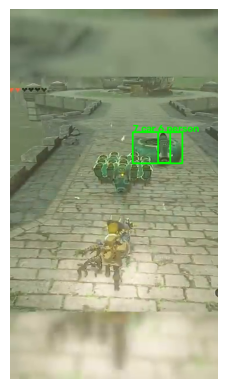

In [11]:
import cv2
import matplotlib.pyplot as plt

stream_tracker = ObjectTracker()
cap = cv2.VideoCapture(str(ex_vid))
try:
    for _ in range(30):
        success, frame = cap.read()
        if not success:
            break
        tracked = stream_tracker.track_frame(frame)
finally:
    cap.release()

annotated = frame.copy()
for obj in tracked:
    b = obj.bounding_box
    p1, p2 = (int(b.x_min), int(b.y_min)), (int(b.x_max), int(b.y_max))
    cv2.rectangle(annotated, p1, p2, (0, 255, 0), 2)
    cv2.putText(annotated, f"{obj.track_id} {obj.class_name}", p1,
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")

## Error Handling

The interface fails fast with specific exceptions. All tracking errors are subclasses of `TrackingDomainError`:

- `MissingTrackingIdError`: the detector output has no tracking IDs
- `TrackingConfigurationError`: the model returned a class ID that is not in its class mapping
- `BoundingBoxDimensionError` and `ConfidenceScoreBoundsError`: malformed detector values

`track_video` also raises `FileNotFoundError` if the video path does not exist.

In [12]:
from mediatools.vision import TrackingDomainError

try:
    for frame in ObjectTracker().track_video(ex_vid):
        pass
except TrackingDomainError as e:
    print(f"Tracking failure: {e}")

In [13]:
zd.cleanup()